# Data Guide 2: Zimbabwe data preparation and model comparisons

**From crop-cut measurements to the Lacuna–2024 merge, weather enrichment and the compact-feature experiment.**

This is the companion to [Data Guide 1](data_guide.ipynb). Guide 1 explains the original multi-country data foundation;
this notebook explains the Zimbabwe work requested for the midterm and the follow-up experiments.
The country is Zimbabwe, not Malawi: the target is Lacuna 2023, and Zimbabwe 2024 supplies auxiliary training data.

**What we learned:** units and keys can be harmonized, but the two cohorts are different seasons and populations.
Naive pooling hurts. Richer imagery helps more than adding 2024. Forty-six weather features made the tree models worse;
smaller sets recover some of that loss. Four-feature shared Ridge is a promising candidate, but its advantage over the
best imagery-only model is too uncertain to call an overall improvement.

The code below reads the actual released tables and saved predictions. Tables and figures are calculated from those files;
they are not hand-entered presentation numbers. No new blind-test claim is made.

## How to use this notebook

Run the cells from top to bottom with the repository's Python environment (`pip install -r requirements.txt`).
The default path needs the tracked releases, **no network access and no DuckDB database**. It checks hashes, joins, units,
splits and scores, then explains the saved experiments. It does not download data, change labels, regenerate splits or retrain models.
An optional one-fold model replay appears near the end; the full experiments have separate scripts.

1. Files, providers and the meaning of one row.
2. Cleaning, yield conversion and the row-count funnel.
3. Appending cohorts, season alignment and measurement limits.
4. Features, spatial splits and leakage protection.
5. First merge results and source-quality diagnostics.
6. Weather provenance, units and drought context.
7. Compact weather, overfitting and uncertainty.
8. Trace a field, reproduce the work and explain the choices.

For a short overview, read [the report](../docs/ZIMBABWE_COMPLETE_METHODS.md). The technical protocols remain separate from the results.

The [quality-review notebook](data_quality_review.ipynb) covers the earlier cross-country source checks, stricter cloud variant, plot-to-pixel diagrams and foundation-model preparation notes now also merged into main. That variant remains separate from the frozen inputs used here.

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook inside the DSC-291 repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 18)

MIDTERM = ROOT / "data/processed/zimbabwe_midterm_v1"
MERGE = ROOT / "data/runs/zimbabwe_merge_v1"
DIAGNOSIS = ROOT / "data/runs/zimbabwe_transfer_diagnosis_v1"
WEATHER = ROOT / "data/processed/zimbabwe_weather_v1"
FULL = ROOT / "data/runs/zimbabwe_weather_v1"
COMPACT = ROOT / "data/runs/zimbabwe_weather_compact_v1"
RELEASES = [MIDTERM, MERGE, DIAGNOSIS, WEATHER, FULL, COMPACT]

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def digest(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

for directory in RELEASES:
    if not (directory / "manifest.json").is_file():
        raise FileNotFoundError(f"Missing released data: {directory.relative_to(ROOT)}. Pull the complete main branch.")
print("Ready: six versioned releases; no download or database connection.")

Ready: six versioned releases; no download or database connection.


## 1. Files, sources and the meaning of one row

An observation is a **field-season**, not a permanent farm identity. `obs_id` is the stable, source-prefixed join key.
`source_id` and `source_row` link back to the provider. `domain` distinguishes Lacuna from the 2024 study.
`season_year` is the harvest/collection year used for calendar alignment.

The catalog preserves screened labels even when they are not eligible for a particular model.
The modeling table is narrower. An exported row is not automatically authorized for training.

In [2]:
catalog = pd.read_parquet(MERGE / "harmonized_labels.parquet").set_index("obs_id").sort_index()
rows = pd.read_parquet(MERGE / "combined_data.parquet").set_index("obs_id").sort_index()
rows["group_id"] = rows.group_id.astype(str)
enriched = pd.read_parquet(WEATHER / "harmonized_labels_weather.parquet").set_index("obs_id").sort_index()
lacuna_audit = pd.read_csv(MIDTERM / "row_audit.csv")
source_audit = pd.read_csv(MERGE / "source_2024_audit.csv")
summary = read_json(MERGE / "data_summary.json")
target_all = rows[rows.domain.eq("lacuna")]
development = target_all[target_all.fold.isin([1, 2, 3, 4])]
source = rows[rows.domain.eq("zimbabwe_2024") & rows.feature_eligible]

assert catalog.index.is_unique and rows.index.is_unique and enriched.index.is_unique
assert (len(catalog), len(rows), len(target_all), len(development), len(source)) == (6598, 6212, 1880, 1504, 4330)
pd.testing.assert_frame_equal(catalog, enriched[catalog.columns])
display(pd.DataFrame([
    ["All screened Zimbabwe labels", len(catalog), "Lacuna 2022/2023 + Zimbabwe 2024"],
    ["Comparison candidates", len(rows), "Lacuna primary 2023 + all screened 2024"],
    ["Primary Lacuna", len(target_all), "1,504 development + 376 reserved"],
    ["Source with sufficient imagery", len(source), "Before fit-specific spatial exclusions"],
], columns=["Table/population", "Rows", "Meaning"]))

,Table/population,Rows,Meaning
0,All screened Zimbabwe labels,6598,Lacuna 2022/2023 + Zimbabwe 2024
1,Comparison candidates,6212,Lacuna primary 2023 + all screened 2024
2,Primary Lacuna,1880,"1,504 development + 376 reserved"
3,Source with sufficient imagery,4330,Before fit-specific spatial exclusions


### Provider attribution

| Input | Provider and original source | What we use |
|---|---|---|
| Lacuna | PULA Advisors, [Zenodo 10060610](https://doi.org/10.5281/zenodo.10060610), version 1.1.1, published 2023 | GeoJSON labels, crop cuts, dates and management |
| Zimbabwe 2024 | Irgau et al., [Zenodo 17626117](https://doi.org/10.5281/zenodo.17626117), published 2025; [paper](https://arxiv.org/html/2511.12999v1) | Public crop-cut metadata; photos are not model inputs |
| Satellite imagery | Sentinel-2 L2A, Earth Search `sentinel-2-c1-l2a` | Existing monthly bands and vegetation indices from the pinned team database |
| Weather | NASA POWER / MERRA-2, [monthly API](https://power.larc.nasa.gov/docs/services/api/temporal/monthly/) | Monthly corrected precipitation and 2 m temperature, 1991–2024 |

Both label releases have CC BY 4.0 recorded in their saved metadata. Retain provider attribution and [NASA POWER attribution](https://power.larc.nasa.gov/docs/referencing/).
The 2024 dataset's release date is 2025; release year and crop year are different concepts.
The paper's zone-filtered sample is not identical to our screened public-label population.

### Check that the released files have not changed

A manifest is a ledger of expected file hashes. This cell checks every output in the six releases and the raw weather snapshots.
It checks the data and artifacts we are reading. Full input/code/database verification is a separate reproduction step;
a passed output-hash check alone does not certify the current code or establish scientific correctness.

In [3]:
verified = []
for directory in RELEASES:
    manifest = read_json(directory / "manifest.json")
    for name, record in manifest["outputs"].items():
        assert digest(directory / name) == record["sha256"], f"Changed released file: {directory.name}/{name}"
    verified.append({"release": directory.name, "output_files_verified": len(manifest["outputs"])})
ledger = pd.read_csv(WEATHER / "weather_retrieval_ledger.csv")
for item in ledger.itertuples():
    assert digest(ROOT / item.raw_path) == item.response_sha256
display(pd.DataFrame(verified))
print(f"Also verified {len(ledger)} exact NASA POWER response snapshots.")

,release,output_files_verified
0,zimbabwe_midterm_v1,17
1,zimbabwe_merge_v1,16
2,zimbabwe_transfer_diagnosis_v1,26
3,zimbabwe_weather_v1,13
4,zimbabwe_weather_v1,22
5,zimbabwe_weather_compact_v1,22


Also verified 97 exact NASA POWER response snapshots.


## 2. Clean the data before interpreting the models

Lacuna's raw file contains several crops. We start with its 2,269 maize observations.
Three records fail the 40 m² yield conversion. We retain their audit trail and exclude them.
We then keep the intended **2023, pure-stand, rainfed** population for the target comparison.
The 2022 rows remain in the catalog; their pinned imagery has only three or four observed months and the inherited exclusion remains.
The counts below are sequential, so exclusions are not double-counted.

In [4]:
a = lacuna_audit
screened = a[a.screened_in]
year2023 = screened[screened.season_year.eq(2023)]
pure = year2023[~year2023.intercropped]
rainfed = pure[~pure.irrigated]
funnel = pd.DataFrame([
    ["Raw maize", len(a)], ["Pass raw measurement screens", len(screened)],
    ["Harvest year 2023", len(year2023)], ["Pure stand", len(pure)], ["Rainfed primary target", len(rainfed)],
], columns=["Stage", "Rows"])
funnel["Removed at this stage"] = funnel.Rows.shift().sub(funnel.Rows).fillna(0).astype(int)
assert funnel.Rows.tolist() == [2269, 2266, 2097, 1885, 1880]
display(funnel)
display(a.exclusion_reason.fillna("retained primary").value_counts().rename_axis("Recorded reason").to_frame("Rows"))

,Stage,Rows,Removed at this stage
0,Raw maize,2269,0
1,Pass raw measurement screens,2266,3
2,Harvest year 2023,2097,169
3,Pure stand,1885,212
4,Rainfed primary target,1880,5


,Rows
Recorded reason,
retained primary,1880
lacuna_intercropped,212
dropped_year_2022_imagery_gap,169
lacuna_irrigated,5
failed_raw_screen,3


### A yield conversion you can explain by hand

Yield in kg/ha = dry mass in kg × 10,000 / cut area in m².
Yield in t/ha = dry mass in kg × 10 / cut area in m².
For **40 m²**, this is **dry kg × 0.25**. A 10 kg dry crop cut represents 2.5 t/ha.

The three anomalous Lacuna records imply ×0.5. We cannot infer whether the area, mass or recorded yield is wrong,
so automatically halving them would invent a repair. The remaining arithmetic supports metric tonnes per hectare;
the public description's “Megatonnes” wording is not used as a unit conversion.

In [5]:
mass_kg, cut_area_m2 = 10.0, 40.0
print(f"{mass_kg:g} dry kg / {cut_area_m2:g} m² → {mass_kg * 10000 / cut_area_m2:g} kg/ha → {mass_kg * 10 / cut_area_m2:g} t/ha")
bad = a[a.yield_conversion_mismatch].copy()
bad["reported_yield_per_dry_kg"] = bad.source_yield_t_ha / bad.dry_weight_kg
assert len(bad) == 3
display(bad[["obs_id", "dry_weight_kg", "source_yield_t_ha", "expected_t_ha_from_dry_weight", "reported_yield_per_dry_kg"]])
ok = a[a.screened_in]
np.testing.assert_allclose(ok.source_yield_t_ha, ok.dry_weight_kg * .25, rtol=0, atol=1e-6)

10 dry kg / 40 m² → 2500 kg/ha → 2.5 t/ha


,obs_id,dry_weight_kg,source_yield_t_ha,expected_t_ha_from_dry_weight,reported_yield_per_dry_kg
2052,zimbabwe:54fa2e37-83b0-4dd8-81df-f0a9c9999862,2.9625,1.48125,0.740625,0.5
2107,zimbabwe:e96a434f-c284-4d94-8bee-8a8c58394000,0.7850,0.39250,0.196250,0.5
2189,zimbabwe:1268f497-44a3-4347-9fb5-3822256e4269,0.9025,0.45125,0.225625,0.5


### Zimbabwe 2024: distinguish missing measurements from zero yields

There are 5,055 raw maize records. **723 lack usable yield labels** and are excluded without label imputation:
590 are described as photos only and 133 have wet weight without dry weight in the raw review.
The remaining **4,332 labels include 1,874 recorded zeros and 42 single-cut records**.
A zero is not the same state as an unmeasured yield; drought or visit timing alone does not prove a particular zero valid or invalid.

Check each available box's mass-to-yield conversion, then the mean of available box yields, with a tolerance of 0.000001 t/ha.
Never divide an already averaged yield by two again. Dry mass cannot exceed a reported wet mass.

In [6]:
s = source_audit
display(s.outcome_status.value_counts().rename_axis("Outcome status").to_frame("Raw rows"))
kept = s[s.label_eligible]
assert len(kept) == 4332 and s.yield_t_ha.isna().sum() == 723
assert kept.yield_t_ha.eq(0).sum() == 1874 and kept.n_cuts_observed.eq(1).sum() == 42
np.testing.assert_allclose(kept.yield_t_ha, kept.recomputed_yield_t_ha, rtol=0, atol=1e-6)
example = kept[kept.n_cuts_observed.eq(2) & kept.yield_t_ha.gt(0)].iloc[0]
display(example[["obs_id", "box1_dry_kg", "box2_dry_kg", "box1_yield_t_ha", "box2_yield_t_ha", "yield_t_ha", "recomputed_yield_t_ha"]].to_frame("Example field"))

,Raw rows
Outcome status,
recorded_positive,2458
recorded_zero,1874
missing,723


,Example field
obs_id,vision_guided_yield_estimation:00402243-ef09-4...
box1_dry_kg,0.235
box2_dry_kg,0.19
box1_yield_t_ha,0.05875
box2_yield_t_ha,0.0475
yield_t_ha,0.053125
recomputed_yield_t_ha,0.053125


## 3. What merging means, and what it does not solve

We **append field-season rows vertically** after harmonizing units and column meanings. We do not join farmers across years,
average their outcomes or infer farm identity from nearby coordinates. There is no verified common farm key.

| Issue | Treatment | Remaining limitation |
|---|---|---|
| Units/area | Independently check t/ha and kg/ha; both sources use 40 m² cuts | Some raw units remain flagged as provisional |
| One versus two cuts | Preserve available-cut counts and use the provider's verified mean | Sampling precision differs; no universal noise multiplier |
| Moisture | Preserve unknown moisture basis | No correction without observed moisture values |
| Missing versus zero yield | Exclude missing labels; retain recorded zeros and test sensitivities | A retained zero is not independently certified |
| Crop dates/management | Target remains pure-stand rainfed 2023; keep source unknowns | Provider, management and year are confounded |
| GPS/field area | Preserve point locations; group/buffer spatial neighbors | A point pixel is not an entire field or the exact cut footprint |

A physical moisture correction would be `Y_target = Y_observed × (100 − m_observed)/(100 − m_target)`.
The moisture values are absent; statistical calibration is not a replacement for them.

In [7]:
display(catalog.groupby(["domain", "season_year"]).agg(
    labels=("yield_t_ha", "size"), mean_yield_t_ha=("yield_t_ha", "mean"),
    zero_share=("is_zero", "mean"), comparison_candidates=("comparison_candidate", "sum")
).round(3))
assert set(rows.index) == set(catalog[catalog.comparison_candidate].index)
assert rows.loc[rows.domain.eq("lacuna"), "season_year"].eq(2023).all()
assert source.season_year.eq(2024).all()
assert catalog.moisture_basis_pct.isna().all()

labels  mean_yield_t_ha  zero_share  \
domain        season_year                                        
lacuna        2022            169            2.457       0.000   
              2023           2097            3.331       0.013   
zimbabwe_2024 2024           4332            0.486       0.433   

                           comparison_candidates  
domain        season_year                         
lacuna        2022                             0  
              2023                          1880  
zimbabwe_2024 2024                          4332

### Same calendar position, different seasons

| Label year | Weather season | Shared imagery window | Use |
|---|---|---|---|
| 2022 | Oct 2021–Jun 2022 | Outside the comparison | Catalog and audit |
| 2023 | Oct 2022–Jun 2023 | Dec 2022–Jun 2023 | Lacuna target |
| 2024 | Oct 2023–Jun 2024 | Dec 2023–Jun 2024 | Auxiliary training source |

December–June is the common seven-month imagery window because October/November 2022 is absent from the pinned collection.
Require at least four observed months and finite seasonal summaries: all 1,880 target fields and 4,330 of 4,332 sources pass.
Missing month values are handled inside each training fold.

**This is retrospective estimation, not a historical 2023 forecast.** The audit finds post-harvest imagery for 1,810 target fields.
Later-year training labels and full-season imagery/weather would not have been available at a real-time 2023 forecast date.

In [8]:
audit_summary = read_json(MIDTERM / "audit_summary.json")
display(rows.groupby(["domain", "observed_months", "feature_eligible"]).size().rename("fields").reset_index())
display(pd.DataFrame([
    ["Target fields with post-harvest scenes", audit_summary["postharvest_fields"], 1880],
    ["Primary zero yields retained", audit_summary["zero_yield_primary"], 1880],
    ["Source fields excluded for imagery", int((~rows[rows.domain.eq("zimbabwe_2024")].feature_eligible).sum()), 4332],
], columns=["Audit finding", "Count", "Denominator"]))

,domain,observed_months,feature_eligible,fields
0,lacuna,4,True,15
1,lacuna,5,True,242
2,lacuna,6,True,621
3,lacuna,7,True,1002
4,zimbabwe_2024,3,False,2
5,zimbabwe_2024,4,True,2
6,zimbabwe_2024,5,True,10
7,zimbabwe_2024,6,True,428
8,zimbabwe_2024,7,True,3890


,Audit finding,Count,Denominator
0,Target fields with post-harvest scenes,1810,1880
1,Primary zero yields retained,28,1880
2,Source fields excluded for imagery,2,4332


### Why more rows did not automatically help

The target development yield mean is about 3.23 t/ha, while the eligible 2024 source mean is about 0.49 t/ha.
This is a strong distribution difference, not proof of a conversion error. Unweighted pooling gives the larger, lower-yield source
substantial influence and can pull target predictions downward. The two distributions below are kept separate.

,Lacuna development,Eligible Zimbabwe 2024
count,1504.000,4330.000
mean,3.234,0.486
std,1.985,0.854
min,0.000,0.000
5%,0.508,0.000
50%,2.903,0.093
95%,6.873,2.184
max,12.430,9.111


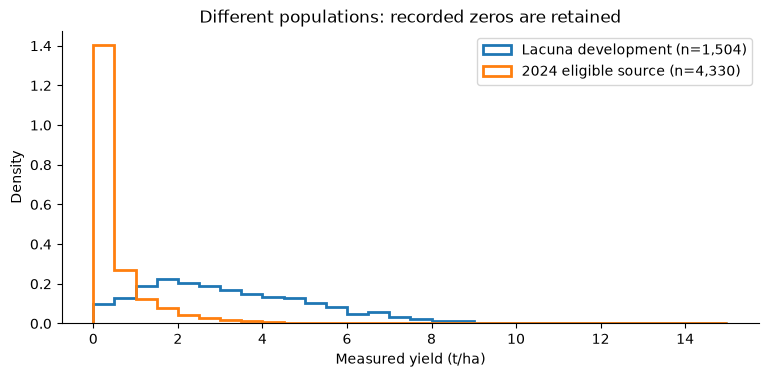

In [9]:
yield_summary = pd.DataFrame({
    "Lacuna development": development.yield_t_ha.describe(percentiles=[.05, .5, .95]),
    "Eligible Zimbabwe 2024": source.yield_t_ha.describe(percentiles=[.05, .5, .95]),
})
display(yield_summary.round(3))
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.arange(0, 15.5, .5)
ax.hist(development.yield_t_ha, bins=bins, density=True, histtype="step", lw=2, label="Lacuna development (n=1,504)")
ax.hist(source.yield_t_ha, bins=bins, density=True, histtype="step", lw=2, label="2024 eligible source (n=4,330)")
ax.set(xlabel="Measured yield (t/ha)", ylabel="Density", title="Different populations: recorded zeros are retained")
ax.legend(); plt.show()

## 4. Features and evaluation rules

The model input is an explicit feature matrix; it is **not every numeric column in the merged table**.
Yield, dry weights, source outcome components, IDs, split labels and audit decisions must not accidentally become predictors.
Coordinates and weather-grid IDs are not ordinary predictors in these weather models. Merged trees deliberately receive a cohort indicator.

| Representation | Columns | Meaning |
|---|---:|---|
| Seasonal imagery | 10 | Mean/max of five vegetation indices |
| Monthly imagery | 122 | Ten seasonal summaries + 105 monthly band/index values + seven missing-scene masks |
| Presto | 128 | Frozen embeddings; different whole-window/masking convention |
| Monthly + full weather | 168 | 122 imagery + 46 weather |
| Monthly + compact weather | 124 or 126 | 122 imagery + two or four weather summaries |

Within every inner or outer fit, imagery imputation, 1st/99th percentile clipping and scaling use **target training rows only**.
Weather receives training-only imputation/scaling without percentile clipping, so genuine source drought extremes remain visible.

In [10]:
monthly = pd.read_parquet(DIAGNOSIS / "features_monthly.parquet").reindex(rows.index)
compact2 = pd.read_parquet(COMPACT / "features_compact2.parquet").reindex(rows.index)
compact4 = pd.read_parquet(COMPACT / "features_compact4.parquet").reindex(rows.index)
compact_config = read_json(ROOT / "configs/zimbabwe_weather_compact_v1.json")
assert [monthly.shape[1], compact2.shape[1], compact4.shape[1]] == [122, 124, 126]
for matrix in [monthly, compact2, compact4]:
    assert matrix.index.equals(rows.index)
    assert not {"yield_t_ha", "yield_kg_ha", "fold", "lat", "lon", "group_id"}.intersection(matrix.columns)
pd.testing.assert_frame_equal(monthly, compact4[monthly.columns])
display(pd.DataFrame({"weather set": ["two", "four"], "columns": [compact_config["feature_sets"]["compact2"], compact_config["feature_sets"]["compact4"]]}))
display(monthly.iloc[:3, :8])

,weather set,columns
0,two,"[wx_rain_percent_normal_jan_mar, wx_t2m_anomal..."
1,four,"[wx_rain_percent_normal_jan_mar, wx_t2m_anomal..."


,ndvi_season_max,ndvi_season_mean,gcvi_season_max,gcvi_season_mean,mtci_season_max,mtci_season_mean,ndvi705_season_max,ndvi705_season_mean
obs_id,,,,,,,,
vision_guided_yield_estimation:0012b17c-5067-408d-b46b-0d2a9f966edc,0.329904,0.205387,1.296954,0.916109,18.255144,5.282491,0.266754,0.147073
vision_guided_yield_estimation:00250a71-8a9e-4efb-82f0-39757ad293e3,0.579433,0.296262,3.020134,1.794823,3.279976,2.079218,0.391102,0.184916
vision_guided_yield_estimation:00402243-ef09-4a58-903e-a1a24c40f1cf,0.404632,0.352498,1.784641,1.627424,47.049544,15.232751,0.354119,0.327853


### Keep the same target fields and spatial splits

The `s1_cc2km` groups are connected components of nearby points, not surveyed village IDs.
The initial handoff used folds 2–4 for training, fold 1 for validation and fold 0 as a historically evaluated test set.
The merge experiments rotate **development folds 1–4** as outer evaluation folds; each has 376 fields.
Each outer model trains on 1,128 target fields. Its three inner splits train on 752 and validate on 376.

**Target fold 0 stays excluded from all new fitting and scoring.** It is reserved here, but earlier use means it is not newly blind.
For each fit, remove source points within 2 km of reserved, outer-evaluation or inner-validation target points.
That prevents a nearby 2024 observation from undermining target spatial separation.

In [11]:
membership = pd.read_csv(MERGE / "target_memberships.csv", dtype={"group_id": str})
permissions = pd.read_csv(MERGE / "source_spatial_permissions.csv")
for directory in [DIAGNOSIS, FULL, COMPACT]:
    for name in ["target_memberships.csv", "source_spatial_permissions.csv"]:
        assert (directory / name).read_bytes() == (MERGE / name).read_bytes()
reserved_ids = set(target_all[target_all.fold.eq(0)].index)
for (outer, inner), part in membership.groupby(["outer_fold", "inner_fold"]):
    train = part[part.role.eq("fit")]
    query = part[part.role.isin(["evaluation", "validation"])]
    assert set(train.group_id).isdisjoint(query.group_id)
    assert reserved_ids.isdisjoint(train.obs_id) and reserved_ids.isdisjoint(query.obs_id)
allowed = permissions[permissions.allowed_by_spatial_rule]
assert allowed.minimum_distance_to_protected_km.ge(2).all()
display(membership[membership.outer_fold.eq(1)].groupby(["inner_fold", "role"]).size().rename("fields").to_frame())
display(allowed[allowed.inner_fold.eq(0)].groupby("outer_fold").agg(
    allowed_source_fields=("obs_id", "size"), nearest_protected_target_km=("minimum_distance_to_protected_km", "min")
).round(4))
print("Exact split/permission files match all experiments; no target fold-0 fit or score.")

fields
inner_fold role              
0          evaluation     376
           fit           1128
           reserved       376
1          fit            752
           validation     376
2          fit            752
           validation     376
3          fit            752
           validation     376

,allowed_source_fields,nearest_protected_target_km
outer_fold,,
1,4226,2.0156
2,4191,2.0646
3,4194,2.0094
4,4213,2.0070


Exact split/permission files match all experiments; no target fold-0 fit or score.


### What the model selection actually sees

Inner target-validation MSE chooses Ridge alpha, tree leaf count and source weight. Outer outcomes never choose those parameters.
Source total weight is `ratio × number_of_target_training_rows`, with candidate ratios 0, 0.1, 0.3 and 1.
Thus 4,000 source rows cannot dominate solely through row count. A selected ratio of zero means the fitted model used no source data.

Ridge alphas: 0.01, 0.1, 1, 10, 100, 1,000. Monthly/weather trees use 7 or 15 leaves, 120 iterations, learning rate 0.05,
minimum leaf size 20, L2=1 and no early stopping. The saved configurations define seeds and any older experiment differences.
This notebook verifies inner selection rather than picking settings from whichever outer score looks best.

In [12]:
selected = pd.read_csv(COMPACT / "selected_parameters.csv")
tuning = pd.read_csv(COMPACT / "tuning.csv")
for chosen in selected.itertuples():
    trials = tuning[tuning.outer_fold.eq(chosen.outer_fold) & tuning.method.eq(chosen.method)]
    best = trials.iloc[np.argmin(trials.inner_rmse_t_ha.to_numpy())]
    key = "leaves" if "tree" in chosen.method else "alpha"
    assert chosen.ratio == best.ratio and getattr(chosen, key) == best[key]
    assert chosen.n_target_train == 1128
display(selected[selected.method.isin(["compact2_tree_transfer", "compact4_tree_transfer", "compact4_shared"])][
    ["method", "outer_fold", "alpha", "leaves", "ratio", "source_available", "source_used", "inner_rmse_t_ha"]
].round(4))

,method,outer_fold,alpha,leaves,ratio,source_available,source_used,inner_rmse_t_ha
4,compact2_tree_transfer,1,NaN,7.0,1.0,4226,4226,1.6111
7,compact4_shared,1,1.0,NaN,1.0,4226,4226,1.6330
9,compact4_tree_transfer,1,NaN,15.0,0.1,4226,4226,1.6219
14,compact2_tree_transfer,2,NaN,15.0,0.3,4191,4191,1.6664
17,compact4_shared,2,10.0,NaN,0.3,4191,4191,1.6688
19,compact4_tree_transfer,2,NaN,15.0,1.0,4191,4191,1.6875
24,compact2_tree_transfer,3,NaN,7.0,0.1,4194,4194,1.6313
27,compact4_shared,3,10.0,NaN,1.0,4194,4194,1.6553
29,compact4_tree_transfer,3,NaN,7.0,1.0,4194,4194,1.6135
34,compact2_tree_transfer,4,NaN,15.0,0.1,4213,4213,1.7041


## 5. First merge experiment and source-quality follow-up

The first comparison used ten seasonal imagery features. Naive pooling increased error and produced strong downward bias.
A source intercept or cohort adaptation removed much of that average offset, but the gain over Lacuna-only was small.

Adaptive Ridge separately centers features and standardizes outcomes within each training cohort, then learns shared and
cohort-specific slopes with target `[x,x,0]/sqrt(2)` and source `[x,0,x]/sqrt(2)`. Target predictions return to target yield units.
Shared Ridge instead preserves physical outcomes and learns common slopes. Tree pooling uses an explicit cohort indicator.
These are statistical models, not evidence that measurement protocols are physically identical.

In [13]:
merge_metrics = pd.read_csv(MERGE / "metrics.csv").set_index("method")
display(merge_metrics[["n", "rmse_t_ha", "mae_t_ha", "bias_t_ha", "r2"]].round(4))
quality_summary = read_json(DIAGNOSIS / "quality_summary.json")
print(f"Share of naive pooling's extra MSE accounted for by squared mean error: {quality_summary['naive_excess_mse_share_from_squared_bias']:.1%}")

,n,rmse_t_ha,mae_t_ha,bias_t_ha,r2
method,,,,,
train_mean,1504,1.9881,1.6217,-0.0000,-0.0039
lacuna_only,1504,1.7968,1.4477,-0.0137,0.1800
pooled_naive,1504,2.2707,1.7243,-1.3818,-0.3096
pooled_intercept,1504,1.7938,1.4478,-0.0126,0.1827
pooled_adaptive,1504,1.7938,1.4460,-0.0206,0.1827
pooled_positive_sensitivity,1504,1.7932,1.4457,-0.0202,0.1833
pooled_zero_weight_sensitivity,1504,1.7934,1.4458,-0.0205,0.1831
lacuna_tree,1504,1.8026,1.4413,-0.0133,0.1747
pooled_tree,1504,1.7992,1.4363,-0.0391,0.1778


Share of naive pooling's extra MSE accounted for by squared mean error: 99.0%


### Was the 2024 data just poor quality?

The follow-up tested a quality subset (two cuts, at least six observed months, relative cut disagreement ≤1),
matched random subsets with the same size and zero/positive composition, relevance weighting, shuffled-source controls,
smaller target training sets, richer monthly predictors and Presto.
Filtering did not establish a gain beyond the controls. The source labels are also learnable within their own population;
that does not prove every label is correct or establish transfer to Lacuna.

Positive paired cuts correlate at about 0.87, while 250 of 2,416 positive pairs differ by more than their mean.
Both systematic population differences and measurement noise remain plausible. Do not label all drought zeros “bad data.”

In [14]:
diagnostic_metrics = pd.read_csv(DIAGNOSIS / "metrics.csv").set_index("method")
quality_rows = pd.read_csv(DIAGNOSIS / "row_quality.csv")
display(pd.DataFrame([quality_summary]).T.rename(columns={0: "value"}))
display(diagnostic_metrics.loc[
    ["seasonal_target", "seasonal_adaptive", "seasonal_quality", "seasonal_matched_606",
     "monthly_target", "monthly_adaptive", "presto_target", "presto_adaptive", "monthly_tree_target", "monthly_tree_transfer"],
    ["rmse_t_ha", "mae_t_ha", "r2"]
].round(4))
display(pd.read_csv(DIAGNOSIS / "source_metrics.csv")[["method", "n", "rmse_t_ha", "r2"]].round(4))
print("Source-only diagnostics use their own protected population; their scores are not directly comparable to Lacuna RMSE.")

,value
box_pearson_all,0.899773
box_pearson_positive,0.868149
missing_labels,723.000000
naive_excess_mse_share_from_squared_bias,0.990348
positive_exactly_equal_cuts,11.000000
positive_median_relative_difference,0.351708
positive_relative_difference_gt_1,250.000000
recorded_zeros,1874.000000
two_cut_n,4290.000000
two_cut_positive_n,2416.000000


,rmse_t_ha,mae_t_ha,r2
method,,,
seasonal_target,1.7968,1.4477,0.1800
seasonal_adaptive,1.7938,1.4460,0.1827
seasonal_quality,1.7938,1.4459,0.1827
seasonal_matched_606,1.7938,1.4459,0.1827
monthly_target,1.6926,1.3223,0.2723
monthly_adaptive,1.6892,1.3184,0.2753
presto_target,1.6815,1.3151,0.2819
presto_adaptive,1.6796,1.3140,0.2834
monthly_tree_target,1.6594,1.2897,0.3006


,method,n,rmse_t_ha,r2
0,coordinates,3764,0.7233,0.2636
1,monthly_ridge,3764,0.7198,0.2706
2,monthly_tree,3764,0.7382,0.2328
3,presto_ridge,3764,0.7287,0.2524
4,seasonal_ridge,3764,0.7411,0.2268
5,training_mean,3764,0.8433,-0.0012


Source-only diagnostics use their own protected population; their scores are not directly comparable to Lacuna RMSE.


## 6. Add rainfall and temperature with a complete provenance trail

We requested NASA POWER monthly `PRECTOTCORR` and `T2M`, community `AG`, for 1991–2024.
The 97 saved responses identify MERRA2, API v2.10.0 and local solar time; retrieval occurred on 7 November 2026 UTC.
Each request has a full URL, grid coordinates, timestamps, units and a response SHA-256.
The [meteorological source documentation](https://power.larc.nasa.gov/docs/methodology/data/sources_meteorology/) explains the regional reanalysis product.

Map field points to nearest grid centers at 0.5° latitude × 0.625° longitude, with no interpolation.
The median field-to-center distance is about 23 km and maximum about 43 km. These are regional estimates, not farm instruments.

In [15]:
weather_summary = read_json(WEATHER / "summary.json")
display(pd.Series(weather_summary, name="weather release").to_frame())
display(ledger[["weather_grid_id", "retrieved_at_utc", "api_version", "source", "time_standard"]].head(4))
display(Markdown("Example archived request: " + ledger.iloc[0].request_url))
example_response = read_json(ROOT / ledger.iloc[0].raw_path)
assert set(example_response["properties"]["parameter"]) >= {"PRECTOTCORR", "T2M"}
display(pd.DataFrame([
    {"parameter": key, **example_response["parameters"][key]}
    for key in ["PRECTOTCORR", "T2M"]
]))

,weather release
api_versions,[v2.10.0]
climatology,1991–2020
field_months,59382
grid_distance_km_max,42.917139
grid_distance_km_median,22.975664
historical_cell_months,39576
labels,6598
missing_weather_rows,0
weather_cells,97
weather_features,46


,weather_grid_id,retrieved_at_utc,api_version,source,time_standard
0,merra2_r136_c338,2026-11-07T10:23:17.315653+00:00,v2.10.0,MERRA2,LST
1,merra2_r137_c333,2026-11-07T10:23:10.121529+00:00,v2.10.0,MERRA2,LST
2,merra2_r137_c334,2026-11-07T10:23:10.121609+00:00,v2.10.0,MERRA2,LST
3,merra2_r137_c335,2026-11-07T10:23:10.446731+00:00,v2.10.0,MERRA2,LST


Example archived request: https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=PRECTOTCORR%2CT2M&community=AG&latitude=-22.0&longitude=31.25&start=1991&end=2024&format=JSON

,parameter,units,longname
0,PRECTOTCORR,mm/day,Precipitation Corrected
1,T2M,C,Temperature at 2 Meters


### Rainfall rate is not rainfall amount

`PRECTOTCORR` is a monthly mean daily rate in **mm/day**. Multiply by the actual days in that month to obtain **mm**.
February 2024 has 29 days. `T2M` is a monthly mean in **°C**; do not sum temperatures.
Annual `YYYY13` API entries are ignored.

Cell/calendar-month normals use exactly 1991–2020. Temperature anomaly subtracts the historical monthly mean.
Seasonal rainfall percent of normal is `100 × sum(actual monthly mm) / sum(normal daily rate × actual month length)`.
Seasonal temperature anomalies are day-weighted. No yields enter these calculations.

In [16]:
history = pd.read_parquet(WEATHER / "weather_history.parquet")
cell_months = pd.read_parquet(WEATHER / "weather_cell_months.parquet")
field_months = pd.read_parquet(WEATHER / "weather_field_months.parquet")
assert len(history) == 97 * 34 * 12 and len(field_months) == 6598 * 9
assert not field_months.duplicated(["obs_id", "month"]).any()
np.testing.assert_allclose(history.rain_total_mm, history.rain_rate_mm_day * history.days_in_month)
february = history[history.year.eq(2024) & history.calendar_month.eq(2)].iloc[0]
assert february.days_in_month == 29
display(february[["weather_grid_id", "year", "calendar_month", "rain_rate_mm_day", "days_in_month", "rain_total_mm", "t2m_c"]].to_frame("Unit example"))
print("Monthly rate-to-amount calculation checked across every historical cell-month.")

,Unit example
weather_grid_id,merra2_r136_c338
year,2024
calendar_month,2
rain_rate_mm_day,1.29
days_in_month,29
rain_total_mm,37.41
t2m_c,28.96


Monthly rate-to-amount calculation checked across every historical cell-month.


### Reconstruct a compact weather record directly

The two-feature set uses January–March rainfall percent of normal and temperature anomaly.
The four-feature set adds the same summaries for the **preceding** October–December.
We fixed these definitions before the compact-model run; we did not search month subsets using held-out yields.
Reducing the set changes both dimensionality and seasonal encoding, so improvement alone cannot identify feature count as the sole cause.

In [17]:
compact_weather = pd.read_parquet(COMPACT / "compact_weather.parquet").reindex(rows.index)
trace_id = development.index[0]
trace = compact_weather.loc[trace_id]
cm = cell_months[cell_months.weather_grid_id.eq(trace.weather_grid_id) & cell_months.season_year.eq(trace.season_year)]
for label, months in [("jan_mar", [1, 2, 3]), ("oct_dec", [10, 11, 12])]:
    part = cm[cm.calendar_month.isin(months)]
    assert len(part) == 3
    if label == "oct_dec":
        assert part.year.eq(trace.season_year - 1).all()
    rain = 100 * part.rain_total_mm.sum() / part.rain_expected_current_days_mm.sum()
    temperature = np.average(part.t2m_anomaly_c, weights=part.days_in_month)
    assert np.isclose(rain, trace[f"wx_rain_percent_normal_{label}"])
    assert np.isclose(temperature, trace[f"wx_t2m_anomaly_c_{label}"])
display(trace[compact_config["feature_sets"]["compact4"]].to_frame("Reconstructed feature"))

,Reconstructed feature
wx_rain_percent_normal_jan_mar,130.587942
wx_t2m_anomaly_c_jan_mar,-1.062363
wx_rain_percent_normal_oct_dec,123.693572
wx_t2m_anomaly_c_oct_dec,-0.920399


### What the weather says about the two years

Compare both seasons on the **same 97 cells**, avoiding a change in location mix. January–March 2024 is drier and hotter
than 2023 in these estimates. This establishes a descriptive weather contrast; it does not identify the causal share of the yield gap.
Monthly averages also cannot reveal consecutive dry days, heat-wave duration or field-specific crop-stage exposure.

,n_weather_cells,wx_rain_total_mm_jan_mar,wx_rain_percent_normal_jan_mar,wx_t2m_anomaly_c_jan_mar
season_year,,,,
2023,97,455.644,117.615,-0.624
2024,97,259.668,63.703,1.350


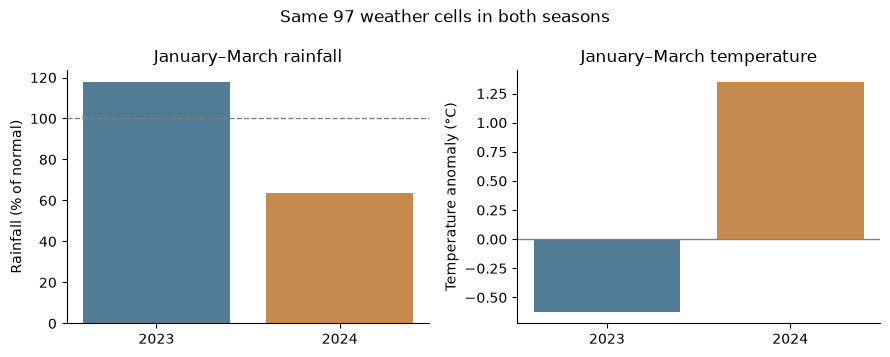

In [18]:
climate = pd.read_csv(FULL / "weather_matched_cell_summary.csv").set_index("season_year")
display(climate[["n_weather_cells", "wx_rain_total_mm_jan_mar", "wx_rain_percent_normal_jan_mar", "wx_t2m_anomaly_c_jan_mar"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].bar(climate.index.astype(str), climate.wx_rain_percent_normal_jan_mar, color=["#527c95", "#c58a50"])
axes[0].axhline(100, ls="--", color="gray", lw=1)
axes[0].set(ylabel="Rainfall (% of normal)", title="January–March rainfall")
axes[1].bar(climate.index.astype(str), climate.wx_t2m_anomaly_c_jan_mar, color=["#527c95", "#c58a50"])
axes[1].axhline(0, color="gray", lw=1)
axes[1].set(ylabel="Temperature anomaly (°C)", title="January–March temperature")
fig.suptitle("Same 97 weather cells in both seasons"); fig.tight_layout(); plt.show()

## 7. Compare no weather, 46 weather features, and compact weather

The original set has 36 monthly weather columns (nine months × four variables) plus ten seasonal aggregates.
The compact experiment adds ten arms: target Ridge, adaptive Ridge, shared Ridge, target trees and merged trees for each small set.
It retains nine unchanged control arms. Earlier 46-feature experiments additionally tested weather-only Ridge and 14 NDVI–weather interactions.

Every result below scores the **same 1,504 target fields**. “Merged” permits source training; inner tuning may select zero source weight.
Do not compare pooled source/target R²: cohort mean differences could create misleading apparent skill.

In [19]:
metrics = pd.read_csv(COMPACT / "metrics.csv").set_index("method")
predictions = pd.read_csv(COMPACT / "predictions.csv", dtype={"group_id": str})
expected_ids = set(development.index)
for method, part in predictions.groupby("method"):
    assert part.obs_id.is_unique and set(part.obs_id) == expected_ids
    assert reserved_ids.isdisjoint(part.obs_id)
    np.testing.assert_array_equal(part.yield_t_ha, rows.loc[part.obs_id, "yield_t_ha"])
    error = part.prediction_t_ha - part.yield_t_ha
    assert np.isclose(np.sqrt(np.mean(error**2)), metrics.loc[method, "rmse_t_ha"], rtol=0, atol=1e-9)
    assert np.isclose(abs(error).mean(), metrics.loc[method, "mae_t_ha"], rtol=0, atol=1e-9)
comparison = []
for name, suffix in [("Target Ridge", "target"), ("Adaptive merged Ridge", "adaptive"), ("Shared merged Ridge", "shared"), ("Target trees", "tree_target"), ("Merged trees", "tree_transfer")]:
    record = {"learner": name}
    for family, label in [("monthly", "No weather"), ("weather", "46 weather"), ("compact2", "2 weather"), ("compact4", "4 weather")]:
        key = f"{family}_{suffix}"
        record[label] = metrics.loc[key, "rmse_t_ha"] if key in metrics.index else np.nan
    comparison.append(record)
display(pd.DataFrame(comparison).set_index("learner").round(4))
print("All 19 score rows independently recomputed from identical target-field predictions. NaN means that arm was not run.")

,No weather,46 weather,2 weather,4 weather
learner,,,,
Target Ridge,1.6926,1.7443,1.6994,1.7283
Adaptive merged Ridge,1.6892,1.7422,1.6960,1.7248
Shared merged Ridge,NaN,1.7499,1.6783,1.6554
Target trees,1.6594,1.6958,1.6806,1.6727
Merged trees,1.6578,1.7221,1.6740,1.7029


All 19 score rows independently recomputed from identical target-field predictions. NaN means that arm was not run.


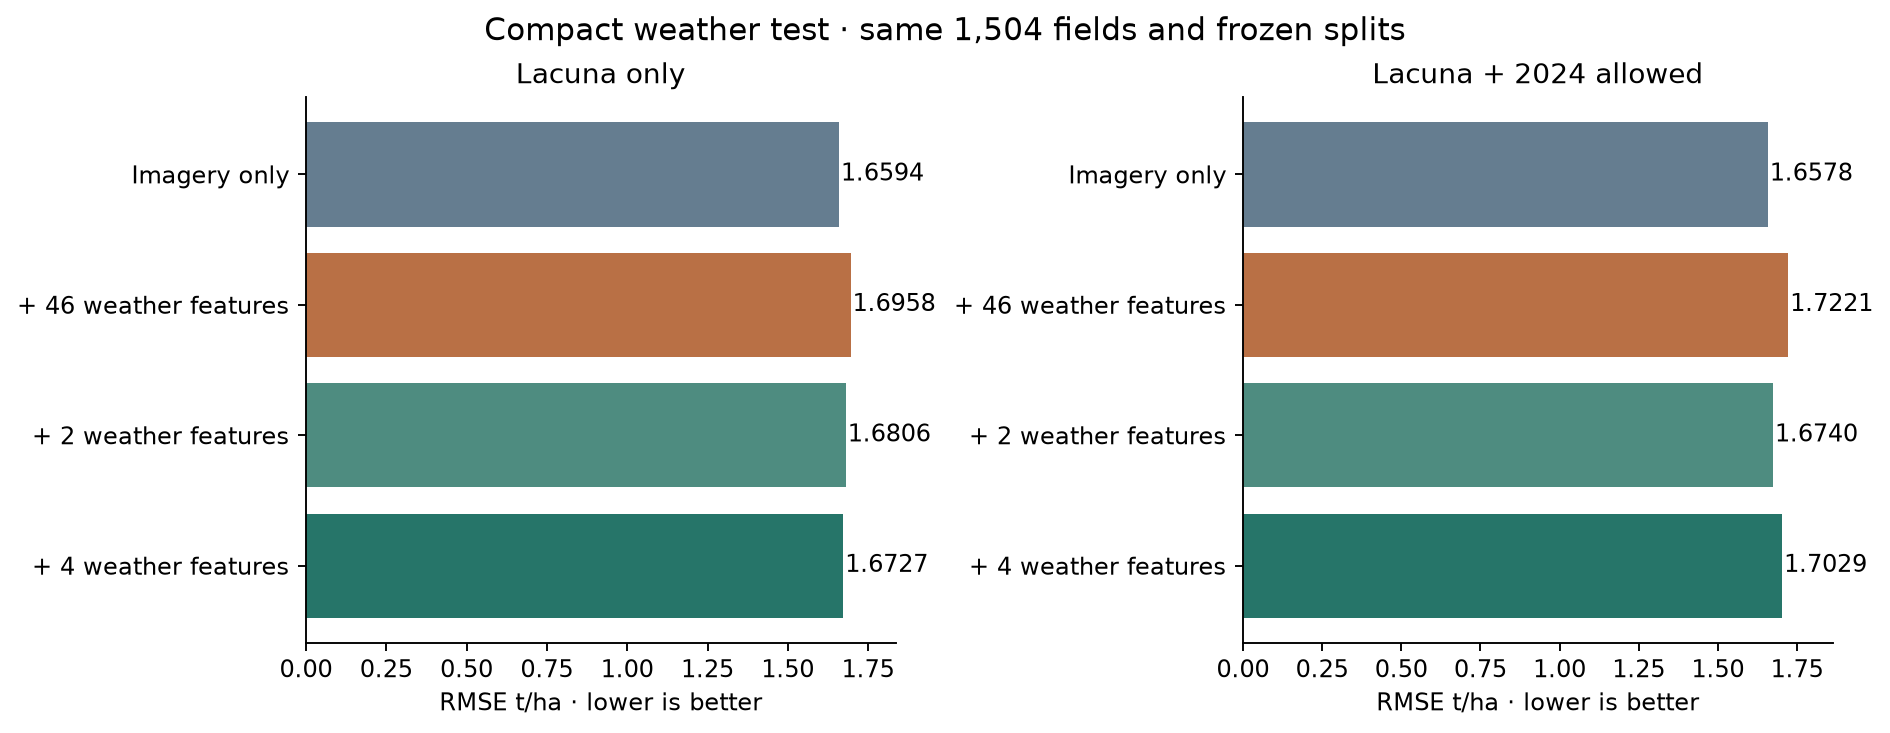

,rmse_t_ha,mae_t_ha,r2
method,,,
weather_only_target,1.9055,1.5123,0.0778
interactions_target,1.7331,1.3513,0.2371
interactions_adaptive,1.7297,1.3479,0.2401
interactions_shared,1.7453,1.3599,0.2263


In [20]:
display(Image(filename=str(COMPACT / "compact_weather_comparison.png")))
full_metrics = pd.read_csv(FULL / "metrics.csv").set_index("method")
display(full_metrics.loc[["weather_only_target", "interactions_target", "interactions_adaptive", "interactions_shared"], ["rmse_t_ha", "mae_t_ha", "r2"]].round(4))

### What supports the overfitting explanation?

Adding the full weather set improves merged-tree training RMSE from about 1.193 to 1.024, while held-out RMSE worsens from 1.658 to 1.722.
That pattern is consistent with fitting training-specific structure. The four-feature merged trees fit training data even more closely,
yet generalize worse than the two-feature trees. Fewer columns alone is not a guarantee against overfitting.

These gaps are descriptive. Selected source weights and leaf counts differ across arms; this is not a controlled causal decomposition
of dimensionality. “Error variance” here means dispersion of prediction errors around their mean, not a formal fitted-model bias–variance decomposition.

,training_rmse,heldout_rmse,gap
method,,,
monthly_tree_transfer,1.1930,1.6578,0.4648
weather_tree_transfer,1.0238,1.7221,0.6984
compact2_tree_transfer,0.9926,1.6740,0.6815
compact4_tree_transfer,0.9152,1.7029,0.7877


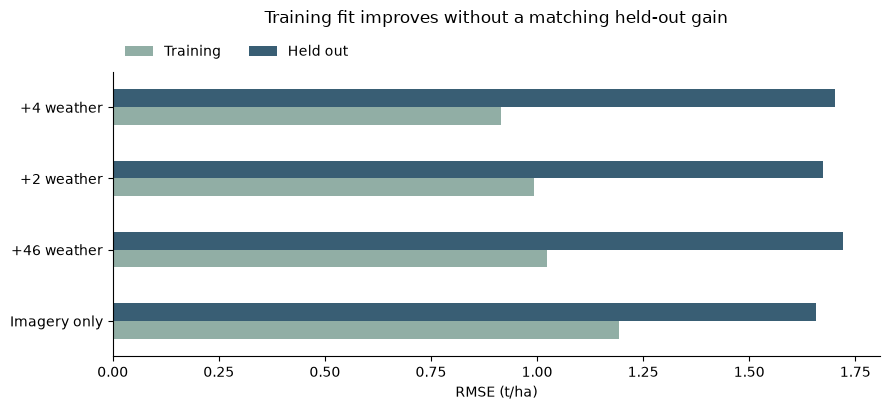

In [21]:
gaps = pd.read_csv(COMPACT / "training_outer_diagnostics.csv")
gap_rows = []
for method in ["monthly_tree_transfer", "weather_tree_transfer", "compact2_tree_transfer", "compact4_tree_transfer"]:
    part = gaps[gaps.method.eq(method)]
    training = np.sqrt(np.mean(part.training_rmse_t_ha**2))
    heldout = np.sqrt(np.mean(part.outer_rmse_t_ha**2))
    gap_rows.append({"method": method, "training_rmse": training, "heldout_rmse": heldout, "gap": heldout - training})
gap_table = pd.DataFrame(gap_rows).set_index("method")
display(gap_table.round(4))
plot_gaps = gap_table[["training_rmse", "heldout_rmse"]].rename(
    index={"monthly_tree_transfer": "Imagery only", "weather_tree_transfer": "+46 weather",
           "compact2_tree_transfer": "+2 weather", "compact4_tree_transfer": "+4 weather"},
    columns={"training_rmse": "Training", "heldout_rmse": "Held out"},
)
ax = plot_gaps.plot.barh(figsize=(9, 4.2), color=["#91aea5", "#395e74"])
ax.set(xlabel="RMSE (t/ha)", ylabel="")
ax.set_title("Training fit improves without a matching held-out gain", pad=35)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

### Redundancy, resolution and weather support

Across 30 target weather cells, the 46-column matrix has 20 feature pairs correlated at |r| ≥0.95; the compact sets have none.
Its centered rank is 29, which is also the maximum for any centered 30-row matrix. Rank alone is not proof of overfitting.

Every eligible 2024 field's January–March temperature anomaly is outside the 2023 target range; about 83% are outside its rainfall range.
Weather can therefore act as a cohort/year marker. A single target season cannot identify a common causal response independently of
provider, management and measurement differences. Successful unit and completeness checks do not establish farm-level weather accuracy.

In [22]:
display(pd.read_csv(COMPACT / "feature_structure.csv"))
support = pd.read_csv(ROOT / "data/runs/zimbabwe_weather_compact_support_v1.csv")
support["source_share_outside_target_range"] = support.source_rows_outside_target_range / support.eligible_source_rows
display(support.round(4))
overlap = pd.read_csv(FULL / "weather_cell_overlap.csv")
outer_overlap = overlap[overlap.inner_fold.eq(0)]
display(outer_overlap)
print(f"Held-out fields sharing a training weather cell: {outer_overlap.query_rows_in_training_weather_cell.sum()} / {outer_overlap.query_rows.sum()}")

,family,weather_features,target_cells,unique_profiles,constant_columns,centered_numerical_rank,high_correlation_pairs
0,compact2,2,30,30,0,2,0
1,compact4,4,30,30,0,4,0
2,full46,46,30,30,0,29,20


,feature,target_min,target_max,source_min,source_max,source_rows_outside_target_range,eligible_source_rows,source_share_outside_target_range
0,wx_rain_percent_normal_jan_mar,80.1280,168.4232,30.1085,135.7754,3601,4330,0.8316
1,wx_t2m_anomaly_c_jan_mar,-1.2078,-0.0062,0.0820,2.3720,4330,4330,1.0000
2,wx_rain_percent_normal_oct_dec,61.9171,123.6936,60.4532,245.3062,2351,4330,0.5430
3,wx_t2m_anomaly_c_oct_dec,-0.9204,0.3294,-0.0211,1.7973,3616,4330,0.8351


,outer_fold,inner_fold,query_rows,query_cells,query_rows_in_training_weather_cell,query_cells_in_training
0,1,0,376,21,376,21
4,2,0,376,23,357,21
8,3,0,376,25,338,23
12,4,0,376,21,376,21


Held-out fields sharing a training weather cell: 1447 / 1504


### Uncertainty changes the conclusion

The prespecified primary compact comparison is **four-feature merged trees versus four-feature target trees**.
Its RMSE difference is +0.0302 t/ha: worse in the point estimate, with an interval that includes zero.
Two-feature merged trees recover part of the 46-feature loss, but the improvement is also uncertain.

Four-feature shared Ridge is the best observed compact candidate (RMSE 1.6554). It improves on its four-feature target-only Ridge
counterpart and the full-weather shared Ridge. Its advantage over the existing best imagery-only trees is only 0.0023 t/ha and is uncertain.
That benchmark comparison was examined **after seeing the results**, and must not become a retroactively declared primary test.

Paired bootstraps resample the same groups for both models: 232 spatial groups, plus a 30-weather-cell sensitivity check.
They condition on saved fitted predictions, do not refit models, and do not remove historical reuse or multiple-comparison uncertainty.
Weather-cell bootstrapping changes uncertainty, not the train/test split.

In [23]:
paired = pd.read_csv(COMPACT / "paired_differences.csv")
candidate_checks = pd.read_csv(ROOT / "data/runs/zimbabwe_weather_compact_candidate_v1.csv")
wanted = [
    ("compact4_tree_transfer", "compact4_tree_target"),
    ("compact2_tree_transfer", "weather_tree_transfer"),
    ("compact2_tree_transfer", "monthly_tree_transfer"),
    ("compact4_shared", "compact4_target"),
]
chosen = paired[[tuple(v) in wanted for v in paired[["method", "reference"]].to_numpy()]]
display(chosen[["method", "reference", "bootstrap_unit", "delta_rmse_t_ha", "ci_low", "ci_high", "primary_comparison"]].round(4))
display(candidate_checks[candidate_checks.reference.eq("monthly_tree_transfer")].round(4))
print("Negative differences favor the named method. These intervals are not adjusted for multiple comparisons.")

,method,reference,bootstrap_unit,delta_rmse_t_ha,ci_low,ci_high,primary_comparison
0,compact4_tree_transfer,compact4_tree_target,spatial_group,0.0302,-0.0009,0.0612,True
4,compact2_tree_transfer,monthly_tree_transfer,spatial_group,0.0163,-0.0127,0.0445,False
9,compact2_tree_transfer,weather_tree_transfer,spatial_group,-0.0481,-0.0995,0.0053,False
23,compact4_shared,compact4_target,spatial_group,-0.0729,-0.1181,-0.0361,False
26,compact4_tree_transfer,compact4_tree_target,weather_cell,0.0302,-0.0012,0.0656,False
30,compact2_tree_transfer,monthly_tree_transfer,weather_cell,0.0163,-0.0116,0.0439,False
35,compact2_tree_transfer,weather_tree_transfer,weather_cell,-0.0481,-0.1126,0.0178,False
49,compact4_shared,compact4_target,weather_cell,-0.0729,-0.1287,-0.0348,False


,method,reference,bootstrap_unit,clusters,delta_rmse_t_ha,ci_low,ci_high,comparison_status
2,compact4_shared,monthly_tree_transfer,spatial_group,232,-0.0023,-0.0548,0.0529,posthoc_best_observed_arm_benchmark_not_primary
5,compact4_shared,monthly_tree_transfer,weather_cell,30,-0.0023,-0.0599,0.0706,posthoc_best_observed_arm_benchmark_not_primary


Negative differences favor the named method. These intervals are not adjusted for multiple comparisons.


### Optional: replay one selected model, without retuning

Set `RUN_ONE_MODEL_REPLAY = True` to fit the four-feature shared Ridge for outer fold 1 using its saved inner-selected parameters.
This uses the released feature matrices and the original source permissions. It needs no raw-image download or database.
It demonstrates the exact X/y/split path; it does not evaluate a new model or supply an independent test result.

In [24]:
RUN_ONE_MODEL_REPLAY = False
if RUN_ONE_MODEL_REPLAY:
    from threadpoolctl import threadpool_limits
    from cropyield.experiments.zimbabwe_weather import make_context, predict
    choice = selected[selected.method.eq("compact4_shared") & selected.outer_fold.eq(1)].iloc[0]
    part = membership[membership.outer_fold.eq(1) & membership.inner_fold.eq(0)]
    fit_ids = part[part.role.eq("fit")].obs_id.tolist()
    query_ids = part[part.role.eq("evaluation")].obs_id.tolist()
    source_ids = permissions[permissions.outer_fold.eq(1) & permissions.inner_fold.eq(0) & permissions.allowed_by_spatial_rule].obs_id.tolist()
    context = make_context(rows, compact4, fit_ids, source_ids, query_ids)
    with threadpool_limits(limits=1):
        replay = predict(context, "shared", {"alpha": choice.alpha, "ratio": choice.ratio}, compact_config)
    saved = predictions[predictions.method.eq("compact4_shared")].set_index("obs_id").loc[query_ids, "prediction_t_ha"]
    np.testing.assert_allclose(replay, saved, rtol=0, atol=1e-9)
    print(f"Reproduced {len(query_ids)} held-out predictions; {len(fit_ids)} target and {len(source_ids)} source training rows.")
else:
    print("Model replay skipped. Set RUN_ONE_MODEL_REPLAY=True to run this one selected fit.")

Model replay skipped. Set RUN_ONE_MODEL_REPLAY=True to run this one selected fit.


## 8. Trace one field through the complete pipeline

Follow one development field from the provider linkage to its yield definition, season, weather grid, split membership and saved predictions.
This is how to answer “where did this number come from?” without reconstructing the argument from memory.
Changing `TRACE_ID` below lets you inspect another Lacuna development field.

In [25]:
TRACE_ID = development.index[0]
assert TRACE_ID in development.index
record = enriched.loc[TRACE_ID]
display(record[["source_id", "source_row", "domain", "season_year", "yield_definition", "cut_area_m2", "yield_t_ha", "weather_grid_id", "weather_grid_distance_km"]].to_frame("Field provenance"))
display(membership[membership.obs_id.eq(TRACE_ID) & membership.inner_fold.eq(0)])
display(field_months[field_months.obs_id.eq(TRACE_ID)].sort_values("month")[["month", "rain_total_mm", "t2m_c", "t2m_anomaly_c"]])
display(predictions[predictions.obs_id.eq(TRACE_ID) & predictions.method.isin(["monthly_tree_target", "monthly_tree_transfer", "weather_tree_transfer", "compact2_tree_transfer", "compact4_shared"])][["method", "outer_fold", "yield_t_ha", "prediction_t_ha"]].round(4))

,Field provenance
source_id,002b9802-b084-47a9-9ba6-0e87a828b826
source_row,2226
domain,lacuna
season_year,2023
yield_definition,cut_8x5m_dry_weight
cut_area_m2,40.0
yield_t_ha,3.575
weather_grid_id,merra2_r144_c334
weather_grid_distance_km,21.00747


,obs_id,group_id,outer_fold,inner_fold,role
0,zimbabwe:002b9802-b084-47a9-9ba6-0e87a828b826,65,1,0,fit
5264,zimbabwe:002b9802-b084-47a9-9ba6-0e87a828b826,65,2,0,fit
11656,zimbabwe:002b9802-b084-47a9-9ba6-0e87a828b826,65,3,0,evaluation
15792,zimbabwe:002b9802-b084-47a9-9ba6-0e87a828b826,65,4,0,fit


,month,rain_total_mm,t2m_c,t2m_anomaly_c
38997,2022-10,2.48,28.15,0.662333
38998,2022-11,164.70,24.58,-2.557333
38999,2022-12,150.04,24.16,-0.919000
39000,2023-01,318.99,22.56,-1.689333
39001,2023-02,179.20,22.88,-0.944333
39002,2023-03,30.07,23.25,-0.542000
39003,2023-04,5.10,23.89,1.347667
39004,2023-05,3.10,22.45,2.079000
39005,2023-06,0.30,20.43,2.349000


,method,outer_fold,yield_t_ha,prediction_t_ha
3760,monthly_tree_target,3,3.575,4.7288
4136,monthly_tree_transfer,3,3.575,4.7075
11280,weather_tree_transfer,3,3.575,4.2631
22560,compact2_tree_transfer,3,3.575,5.0284
23688,compact4_shared,3,3.575,4.7368


## Reproduction and deliverables

| Step | Code | Output |
|---|---|---|
| 8 | `scripts/step8_build_zimbabwe_handoff.py` | Audited Lacuna data and explicit partitions |
| 9 | `scripts/step9_compare_zimbabwe_merge.py` | Harmonized catalog, source audit, initial merge experiments |
| 10 | `scripts/step10_diagnose_zimbabwe_transfer.py` | Source quality, richer representations and transfer diagnostics |
| 11 | `scripts/step11_add_zimbabwe_weather.py` | Cached weather, normals, grids and enriched labels |
| 12 | `scripts/step12_compare_zimbabwe_weather.py` | Full-weather/interaction models on unchanged splits |
| 13 | `scripts/step13_compare_compact_weather.py` | Compact-feature comparison and fit-gap diagnostics |

The experiment modules are under `src/cropyield/experiments/`; data preparation is in `src/cropyield/data/handoff.py` and `weather.py`.
Configurations and prespecified protocols are under `configs/` and `docs/`. Output manifests pin code, data and configuration hashes.
Do not overwrite old releases when changing code or data: use a new output directory and report it as a new experiment.

After merging the earlier quality review, main has stronger shared validators. The historical manifests retain their original hashes. Use the [recorded-code runner](../docs/ZIMBABWE_REPRODUCTION.md) for full verification with the matching team database:

```bash
python scripts/reproduce_zimbabwe.py verify-weather
python scripts/reproduce_zimbabwe.py verify-compact
python scripts/reproduce_zimbabwe.py candidate
```

The runner extracts code from commit `e123594` without changing the active checkout and requires a new output destination. Its model stages are `merge`, `diagnosis`, `weather-models` and `compact`; the `weather` stage reuses the saved cache offline. Repeating steps 9, 10, 12 or 13 trains many models and can take substantial time.
**Do not run step 6 on the team database:** it would remove existing Presto embeddings. Use the hash in `configs/team_database_v1.json`.
Saved outputs let this guide run without that database.

For a sequence model, order weather October–June and imagery December–June by actual date; lexical month-number order is wrong across years.
Keep imagery missingness masks. This work supplies the sequences but does not train the proposed GRU.

In [26]:
verification = read_json(ROOT / "data/runs/zimbabwe_weather_compact_validation_v1.json")
display(pd.Series({k: v for k, v in verification.items() if k != "descriptive_weather_support"}, name="Saved independent verification").to_frame())
display(pd.Series(read_json(ROOT / "configs/team_database_v1.json"), name="Expected team database").to_frame())
print("This is a saved verification receipt, not a claim that the full verification scripts ran in this notebook.")

,Saved independent verification
status,passed
arms,19
evaluation_fields_per_arm,1504
compact_feature_rows,6212
new_weather_values_reconstructed,12424
old_controls_unchanged,9
selected_models_checked,40
accounting_records_checked,160
intervals_replayed,52
bootstrap_units,"[232 spatial groups, 30 weather cells]"


,Expected team database
file,data/cropyield.duckdb
bytes,872689664
sha256,e192b9d6021fdae020f9b08123b98648dc4b5274989635...


This is a saved verification receipt, not a claim that the full verification scripts ran in this notebook.


## How to defend the choices to teammates

- **Why merge at all?** Additional data might teach transferable relationships. We tested that claim on unchanged target fields rather than assuming more rows help.
- **Are the seasons the same?** No. Calendar positions align, but 2023 and 2024 are different agricultural seasons.
- **Why not repair every discrepancy?** We convert known units and exclude documented failures. Missing moisture, management and field identities cannot be recovered by arithmetic.
- **Why keep zeros?** Missing labels and recorded zeros are different. Removing drought failures can bias the sample; we use explicit sensitivities and quality controls.
- **How do we prevent leakage?** Spatial target groups, source buffers, training-only transforms, inner-only tuning and no new target fold-0 fitting/scoring.
- **Why did weather hurt?** Training fit improved while held-out accuracy worsened, consistent with overfitting; coarse repeated weather and large year/cohort differences also limit transfer.
- **Did smaller weather solve it?** It helps some learners, especially shared Ridge. It does not establish an overall win over imagery-only trees.
- **What do we recommend?** Keep the imagery-only tree reference and four-feature shared Ridge candidate. Seek independent seasons/regions and better crop-date/weather resolution before stronger claims.

The remaining limitations are part of the result: one target season, historical development-data reuse, unknown moisture/management,
point-to-field mismatch, regional weather cells and post-harvest imagery. Good preprocessing makes these limits explicit; it does not erase them.